# Modelos de **boosting**

Mientras que los algoritmos de bagging y random forest entrenan múltiples árboles en paralelo, intentando reducir la varianza, los modelos de boosting siguen una lógica diferente y secuencial: entrenan árboles uno tras otro, y cada nuevo árbol intenta corregir los errores de los anteriores. El resultado es un modelo final de alta precisión, aunque más propenso a sobreajuste si no se controla.

A continuación, se va a mostrar como implementar dos de los algoritmos de boosting más populares, y compararemos su desempeño frente a un modelo de bosque aleatorio.

In [1]:
import pandas as pd

df = pd.read_csv(
    "http://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None,
    names=['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
           'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
           'hours-per-week', 'native-country', 'income'],
    na_values=' ?'
    )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop(columns=['income'])
y = df['income']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
    )

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

print(X_train.shape)
print(X_test.shape)

(26048, 14)
(6513, 14)


No es necesario procesar valores nulos, pero si es necesario procesar las variables categóricas del dataset:

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    OrdinalEncoder,
    TargetEncoder,
)

orden = [' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th', ' 10th', ' 11th', ' 12th',  # noqa: E501
         ' HS-grad',' Some-college', ' Assoc-acdm', ' Assoc-voc', ' Bachelors', ' Masters',
         ' Prof-school', ' Doctorate']
ore = OrdinalEncoder(categories=[orden], dtype='int')
ohe = OneHotEncoder(sparse_output=False, drop='if_binary')
te = TargetEncoder()

preprocessor = ColumnTransformer(
    transformers=[
        ('cod_education', ore, ['education']),
        ('cod_oh', ohe, ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex']),  # noqa: E501
        ('cod_te', te, ['native-country'])
    ], remainder='passthrough')

Se sintoniza y entrena el modelo:

In [4]:
from scipy.stats import loguniform
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=1))
])

dist = {
    'classifier__n_estimators':range(10, 200),
    'classifier__max_depth': range(3,5)
    }

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=dist,
    scoring='f1_weighted',
    n_iter=20,
    random_state=1
    )

random_search.fit(X_train, y_train)

print(f'Best validation score: {random_search.best_score_:.3f} with parameters: {random_search.best_params_}')  # noqa: E501
print(f'Train score: {random_search.score(X_train, y_train):.3f}')
print(f'Test score: {random_search.score(X_test, y_test):.3f}')

Best validation score: 0.825 with parameters: {'classifier__n_estimators': 121, 'classifier__max_depth': 4}
Train score: 0.826
Test score: 0.820


Estas son las métricas del modelo:

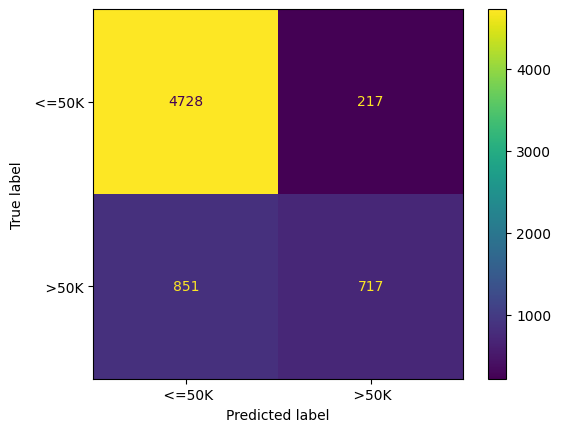

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    random_search.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [6]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    random_search.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.85      0.96      0.90      4945
        >50K       0.77      0.46      0.57      1568

    accuracy                           0.84      6513
   macro avg       0.81      0.71      0.74      6513
weighted avg       0.83      0.84      0.82      6513



En la métrica de evaluación este modelo da buenos resultados, pero claramente está desbalanceado.

Se presenta la importancia relativa de las características del modelo:

In [7]:
best_rf_model = random_search.best_estimator_
importances = best_rf_model.named_steps['classifier'].feature_importances_
features = best_rf_model.named_steps['preprocessor'].get_feature_names_out()

importances_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importances_df = importances_df[importances_df['Importance'] > 0]
importances_df.sort_values('Importance', ascending=False)

,Feature,Importance
12,cod_oh__marital-status_ Married-civ-spouse,0.187094
48,remainder__capital-gain,0.139537
47,remainder__education-num,0.129625
32,cod_oh__relationship_ Husband,0.129055
0,cod_education__education,0.089188
14,cod_oh__marital-status_ Never-married,0.085729
45,remainder__age,0.057350
50,remainder__hours-per-week,0.023472
49,remainder__capital-loss,0.023034
35,cod_oh__relationship_ Own-child,0.019676


## Clasificador AdaBoost

AdaBoost fue el primer algoritmo de boosting exitoso. Su idea central es repesar las muestras:

- Se entrena un árbol débil (normalmente un «stump» o árbol de profundidad 1).
- Se identifican las muestras mal clasificadas.
- Se aumenta el peso de esas muestras difíciles y se reduce el de las bien clasificadas.
- El siguiente árbol se entrena enfocándose en esas muestras con mayor peso.
- Tras cada iteración, se asigna un alpha (importancia) al árbol según su precisión.

La predicción final es la suma ponderada de los predicciones de todos los árboles.

AdaBoost es excelente para clasificación binaria y robusto frente a sobreajuste.

Se va a empezar probando un modelo de AdaBoost sin sintonizar hiperparámetros.

Este modelo, y los modelos de boosting en general, no soportan valores nulos así que se deben procesar:

In [8]:
df_dropna = df.dropna()

X = df_dropna.drop(columns=['income'])
y = df_dropna['income']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
    )

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

print(X_train.shape)
print(X_test.shape)

(24129, 14)
(6033, 14)


In [9]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import f1_score

ada = AdaBoostClassifier(
    n_estimators=50,
    random_state=1,
    )

ada_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', ada)
])

ada_model.fit(X_train, y_train)

train_score = f1_score(y_train, ada_model.predict(X_train), average='weighted')
test_score = f1_score(y_test, ada_model.predict(X_test), average='weighted')
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 0.840
Test score: 0.841


Nótese como este modelo da mejores resultados que el bosque aleatorio y no se sobreajusta, aún sin sintonización de hiperparámetros.

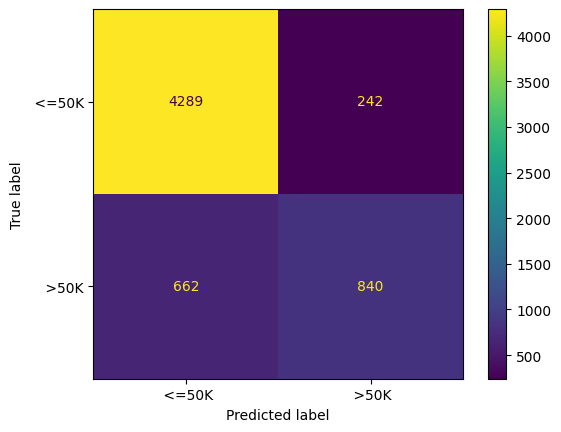

In [10]:
ConfusionMatrixDisplay.from_estimator(ada_model, X_test, y_test, display_labels=le.classes_);

In [11]:
print(classification_report(y_test, ada_model.predict(X_test), target_names=le.classes_))

              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.90      4531
        >50K       0.78      0.56      0.65      1502

    accuracy                           0.85      6033
   macro avg       0.82      0.75      0.78      6033
weighted avg       0.84      0.85      0.84      6033



También se pueden obtener la importancia relativa de cada característica del modelo:

In [12]:
importances = ada_model.named_steps['classifier'].feature_importances_
features = ada_model.named_steps['preprocessor'].get_feature_names_out()

importances_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importances_df = importances_df[importances_df['Importance'] > 0]
importances_df.sort_values('Importance', ascending=False)

,Feature,Importance
45,remainder__capital-gain,0.299552
10,cod_oh__marital-status_ Married-civ-spouse,0.220185
42,remainder__age,0.139727
44,remainder__education-num,0.090261
46,remainder__capital-loss,0.078168
47,remainder__hours-per-week,0.055164
0,cod_education__education,0.030747
18,cod_oh__occupation_ Exec-managerial,0.025909
32,cod_oh__relationship_ Own-child,0.020213
19,cod_oh__occupation_ Farming-fishing,0.015052


A la implementación en Scikit Learn de este algoritmo se le pueden sintonizar dos hiperparámetros: el número de estimadores y la tasa de aprendizaje, o `learning_rate`.

El `learning_rate` es un factor que ajusta la influencia de cada clasificador débil en la combinación final. Este parámetro se multiplica por el peso $\alpha$ de cada clasificador débil durante el proceso de agregación. Así:

- Si `learning_rate` es pequeño, cada clasificador tendrá un menor impacto en el modelo final, lo que puede reducir el riesgo de sobreajuste pero puede requerir más iteraciones para alcanzar un buen desempeño.
- Si `learning_rate` es grande, cada clasificador tendrá un mayor impacto en el modelo final, lo que puede llevar a un sobreajuste si no se tiene cuidado, ya que los clasificadores podrían aprender demasiado rápido y adaptarse demasiado a las particularidades de los datos de entrenamiento.

In [13]:
dist = {
    'classifier__learning_rate':loguniform(1e-3, 10),
    'classifier__n_estimators': range(1, 200)}


random_search = RandomizedSearchCV(
    estimator=ada_model,
    param_distributions=dist,
    scoring='f1_weighted',
    n_iter=20,
    random_state=1
    )

random_search.fit(X_train, y_train)

print(f'Best validation score: {random_search.best_score_:.3f} with parameters: {random_search.best_params_}')  # noqa: E501
print(f'Train score: {random_search.score(X_train, y_train):.3f}')
print(f'Test score: {random_search.score(X_test, y_test):.3f}')

Best validation score: 0.846 with parameters: {'classifier__learning_rate': np.float64(1.2988438590259554), 'classifier__n_estimators': 138}
Train score: 0.848
Test score: 0.850


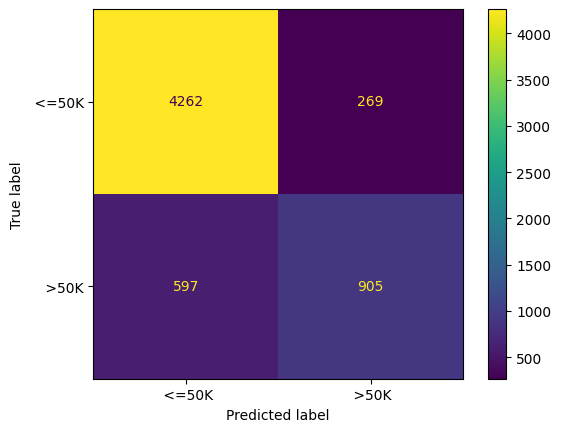

In [14]:
ConfusionMatrixDisplay.from_estimator(
    random_search.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [15]:
print(classification_report(
    y_test,
    random_search.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      4531
        >50K       0.77      0.60      0.68      1502

    accuracy                           0.86      6033
   macro avg       0.82      0.77      0.79      6033
weighted avg       0.85      0.86      0.85      6033



Este algoritmo entrega la importancia relativa de las características del modelo.

In [16]:
best_ada_model = random_search.best_estimator_
importances = best_ada_model.named_steps['classifier'].feature_importances_
features = best_ada_model.named_steps['preprocessor'].get_feature_names_out()

importances_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importances_df = importances_df[importances_df['Importance'] > 0]
importances_df.sort_values('Importance', ascending=False)

,Feature,Importance
45,remainder__capital-gain,0.184247
42,remainder__age,0.160349
10,cod_oh__marital-status_ Married-civ-spouse,0.145823
44,remainder__education-num,0.104120
46,remainder__capital-loss,0.076603
9,cod_oh__marital-status_ Married-AF-spouse,0.068910
30,cod_oh__relationship_ Not-in-family,0.040608
47,remainder__hours-per-week,0.032732
18,cod_oh__occupation_ Exec-managerial,0.021082
24,cod_oh__occupation_ Prof-specialty,0.018420


## Regresor AdaBoost

In [17]:
cols = [
    'mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 
    'acceleration', 'model year', 'origin', 'car name'
    ]

df = pd.read_csv(
    'https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data',
    sep=r'\s+',
    header=None,
    names=cols,
    na_values='?'
    )

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [18]:
X = df.drop(columns=['mpg', 'car name'])
y = df['mpg']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
    )

print('Train:', X_train.shape, y_train.shape)
print('Test:',  X_test.shape, y_test.shape)

Train: (318, 7) (318,)
Test: (80, 7) (80,)


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

rf_model = RandomForestRegressor(
    max_depth=3,
    n_estimators=20,
    random_state=1,
    )

rf_model.fit(X_train, y_train)

train_score = root_mean_squared_error(y_train, rf_model.predict(X_train))
test_score = root_mean_squared_error(y_test, rf_model.predict(X_test))
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 2.785
Test score: 2.366


In [20]:
from scipy.stats import loguniform

dist = {
    'n_estimators':range(1, 201),
    'ccp_alpha':loguniform(1e-4, 1e2),
    'max_features':[4,5,6]
    }

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=dist,
    random_state=1,
    scoring='neg_root_mean_squared_error',
    n_iter=20
    )

random_search.fit(X_train, y_train)

print(f'Best validation score: {-random_search.best_score_:.3f} ')
print(f'Best parameters: {random_search.best_params_}')
print(f'Train score: {-random_search.score(X_train, y_train):.3f}')
print(f'Test score: {-random_search.score(X_test, y_test):.3f}')

Best validation score: 3.264 
Best parameters: {'ccp_alpha': np.float64(0.0026093591654417357), 'max_features': 5, 'n_estimators': 72}
Train score: 2.805
Test score: 2.342


In [21]:
rf_features = pd.DataFrame({
    'Feature': X.columns, 
    'Importance': random_search.best_estimator_.feature_importances_
    })
rf_features.sort_values('Importance', ascending=False)

,Feature,Importance
1,displacement,0.378937
3,weight,0.258199
0,cylinders,0.135138
5,model year,0.129778
2,horsepower,0.095863
4,acceleration,0.001641
6,origin,0.000444


In [22]:
df = df.dropna()

X = df.drop(columns=['mpg', 'car name'])
y = df['mpg']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
    )

print('Train:', X_train.shape, y_train.shape)
print('Test:',  X_test.shape, y_test.shape)

Train: (313, 7) (313,)
Test: (79, 7) (79,)


In [23]:
from sklearn.ensemble import AdaBoostRegressor

ada = AdaBoostRegressor(
    n_estimators=50,
    random_state=1,
    )

ada.fit(X_train, y_train)

train_score = root_mean_squared_error(y_train, ada.predict(X_train))
test_score = root_mean_squared_error(y_test, ada.predict(X_test))
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 2.369
Test score: 3.692


In [25]:
dist = {
    'learning_rate':loguniform(1e-3, 10),
    'n_estimators': range(1, 200)}


random_search = RandomizedSearchCV(
    estimator=ada,
    param_distributions=dist,
    scoring='neg_root_mean_squared_error',
    n_iter=20,
    random_state=1
    )

random_search.fit(X_train, y_train)

print(f'Best validation score: {-random_search.best_score_:.3f} with parameters: {random_search.best_params_}')  # noqa: E501
print(f'Train score: {-random_search.score(X_train, y_train):.3f}')
print(f'Test score: {-random_search.score(X_test, y_test):.3f}')

Best validation score: 2.906 with parameters: {'learning_rate': np.float64(0.480963545373377), 'n_estimators': 72}
Train score: 2.313
Test score: 3.698


In [26]:
ada_features = pd.DataFrame({
    'Feature': X.columns, 
    'Importance': random_search.best_estimator_.feature_importances_
    })
ada_features.sort_values('Importance', ascending=False)

,Feature,Importance
2,horsepower,0.449180
3,weight,0.217258
5,model year,0.165825
1,displacement,0.132643
0,cylinders,0.020710
4,acceleration,0.013156
6,origin,0.001227
